In [1]:
!pip install requests beautifulsoup4 lxml pandas spacy matplotlib seaborn textblob scikit-learn


   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.1 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.1 MB ? eta -:--:--
   ----- ---------------------------------- 0.5/4.1 MB 726.7 kB/s eta 0:00:05
   ----- ---------------------------------- 0.5/4.1 MB 726.7 kB/s eta 0:00:05
   ----- ---------------------------------- 0.5/4.1 MB 726.7 kB/s eta 0:00:05
   ------- -------------------------------- 0.8/4.1 MB 566.8 kB/s eta 0:00:06
   ---------- ----------------------------- 1.0/4.1 MB 611.4 kB/s eta 0:00:05
   ------------ --------------------------- 1.3/4.1 MB 693.8 kB/s eta 0:00:04
   --------------- ------------------------ 1.6/4.1 MB 760.4 kB/s eta 0:00:04
   ------------------ --------------------- 1.8/4.1 MB 817.0 kB/s eta 0:00:03
   -------------------- -------

In [2]:
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     - ------------------------------------- 0.5/12.8 MB 320.2 kB/s eta 0:00:39
     - ------------------------------------- 0.5/12.8 MB 320.2 kB/s eta 0:00:39
     - ------------------------------------- 0.5/12.8 MB 320.2 kB/s eta 0:00:39
     - ------------------------------------- 0.5/12.8 MB 320.2 kB/s eta 0:00:39
     -- ------------------------------------ 0.8/12.8 MB 280.2 kB/s eta 0:00:43
     -- ------------------------------------ 0.8/12.8 MB 280.2 kB/s eta 0:00:43
     -- ------------------------------------ 0.8/12.8 MB 280.2 kB/s eta 0:00:43
     ---

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

In [4]:
urls = [
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html'
]

In [5]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"
}

articles = []

for url in urls:
    try:
        # Fetch the page
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()

        # Parse HTML
        soup = BeautifulSoup(res.content, 'lxml')

        # Extract title
        title = soup.find('h3', class_='post-title')
        title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)

        # Extract article body
        content_div = soup.find('div', class_='post-body entry-content')

        if not content_div:
            continue

        paragraphs = content_div.find_all('p')

        text = ' '.join(
            p.get_text(strip=True)
            for p in paragraphs
        )

        # Skip very short articles
        if len(text) > 100:
            articles.append({
                'url': url,
                'title': title,
                'text': text
            })
        else:
            print(f"[SKIP] Too short: {url}")

        time.sleep(1)

    except Exception as e:
        print(f"[ERROR] {url} -> {e}")

df = pd.DataFrame(articles)

df.head()

[SKIP] Too short: https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html


,url,title,text
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...


In [6]:
df.head()

,url,title,text
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...


In [7]:
df.shape

(4, 3)

In [8]:
df.columns

Index(['url', 'title', 'text'], dtype='str')

In [9]:
import spacy

nlp = spacy.load("en_core_web_sm")

In [10]:
def extract_features(text):
    """Processes text with spaCy and extracts linguistic features."""
    
    doc = nlp(text)
    
    return pd.Series({
        'num_tokens': len(doc),
        'num_sentences': len(list(doc.sents)),
        'num_entities': len(doc.ents),
        'num_nouns': len([t for t in doc if t.pos_ == 'NOUN'])
    })

In [11]:
if not df.empty:
    
    features = df['text'].apply(extract_features)
    
    df = pd.concat([df, features], axis=1)
    
    df['title_length'] = df['title'].apply(len)
    
    print("Features extracted successfully.")
    print(df.head(2))

else:
    print("No articles found for feature extraction.")

Features extracted successfully.
                                                 url  \
0  https://techncruncher.blogspot.com/2025/01/top...   
1  https://techncruncher.blogspot.com/2023/12/lim...   

                                               title  \
0  Top 10 AI Tools That Will Transform Your Conte...   
1  LimeWire AI Studio Review 2023: Details, Prici...   

                                                text  num_tokens  \
0   Looking to level up your content creation gam...        1188   
1   In the rapidly advancing landscape of AI tech...        1723   

   num_sentences  num_entities  num_nouns  title_length  
0             47            24        321            65  
1             65           103        420            59  


In [12]:
from textblob import TextBlob

def get_sentiment(text):
    """Calculates sentiment polarity and subjectivity."""
    
    blob = TextBlob(text)
    
    return pd.Series({
        'sentiment_polarity': blob.sentiment.polarity,
        'sentiment_subjectivity': blob.sentiment.subjectivity
    })

In [13]:
if not df.empty:
    
    sentiment_features = df['text'].apply(get_sentiment)
    
    df = pd.concat([df, sentiment_features], axis=1)
    
    print("Sentiment features extracted successfully.")
    
    print(
        df[
            ['title', 'sentiment_polarity', 'sentiment_subjectivity']
        ].head()
    )

Sentiment features extracted successfully.
                                               title  sentiment_polarity  \
0  Top 10 AI Tools That Will Transform Your Conte...            0.229493   
1  LimeWire AI Studio Review 2023: Details, Prici...            0.219387   
2  Top 10 AI Tools in 2023 That Will Make Your Li...            0.197417   
3  Top 10 AI Content Generator & Writer Tools in ...            0.214853   

   sentiment_subjectivity  
0                0.583603  
1                0.573587  
2                0.436441  
3                0.564907  


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

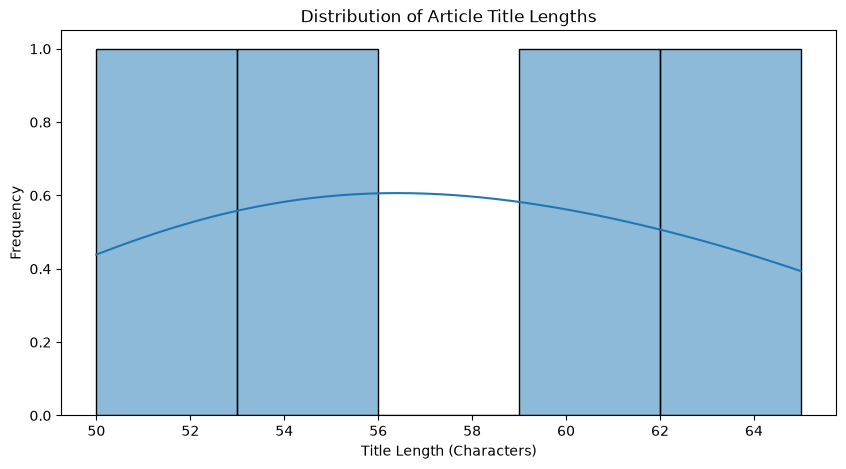

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['title_length'],
    kde=True,
    bins=5
)

plt.title('Distribution of Article Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')

plt.show()

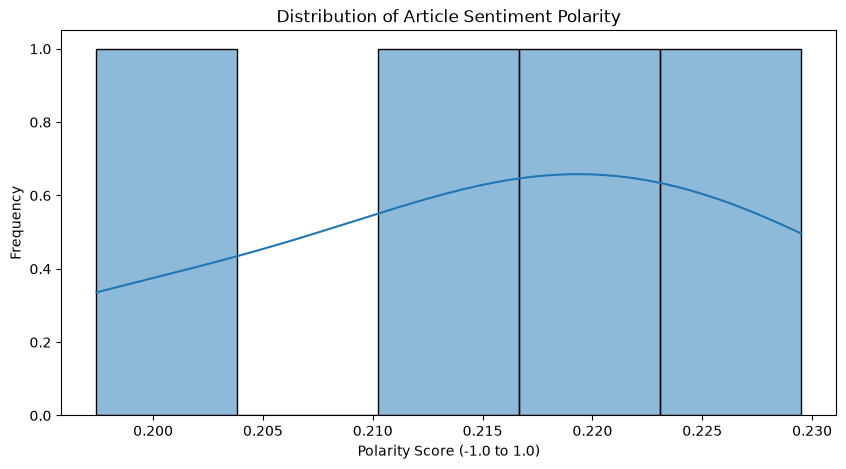

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['sentiment_polarity'],
    kde=True,
    bins=5
)

plt.title('Distribution of Article Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')

plt.show()

In [17]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

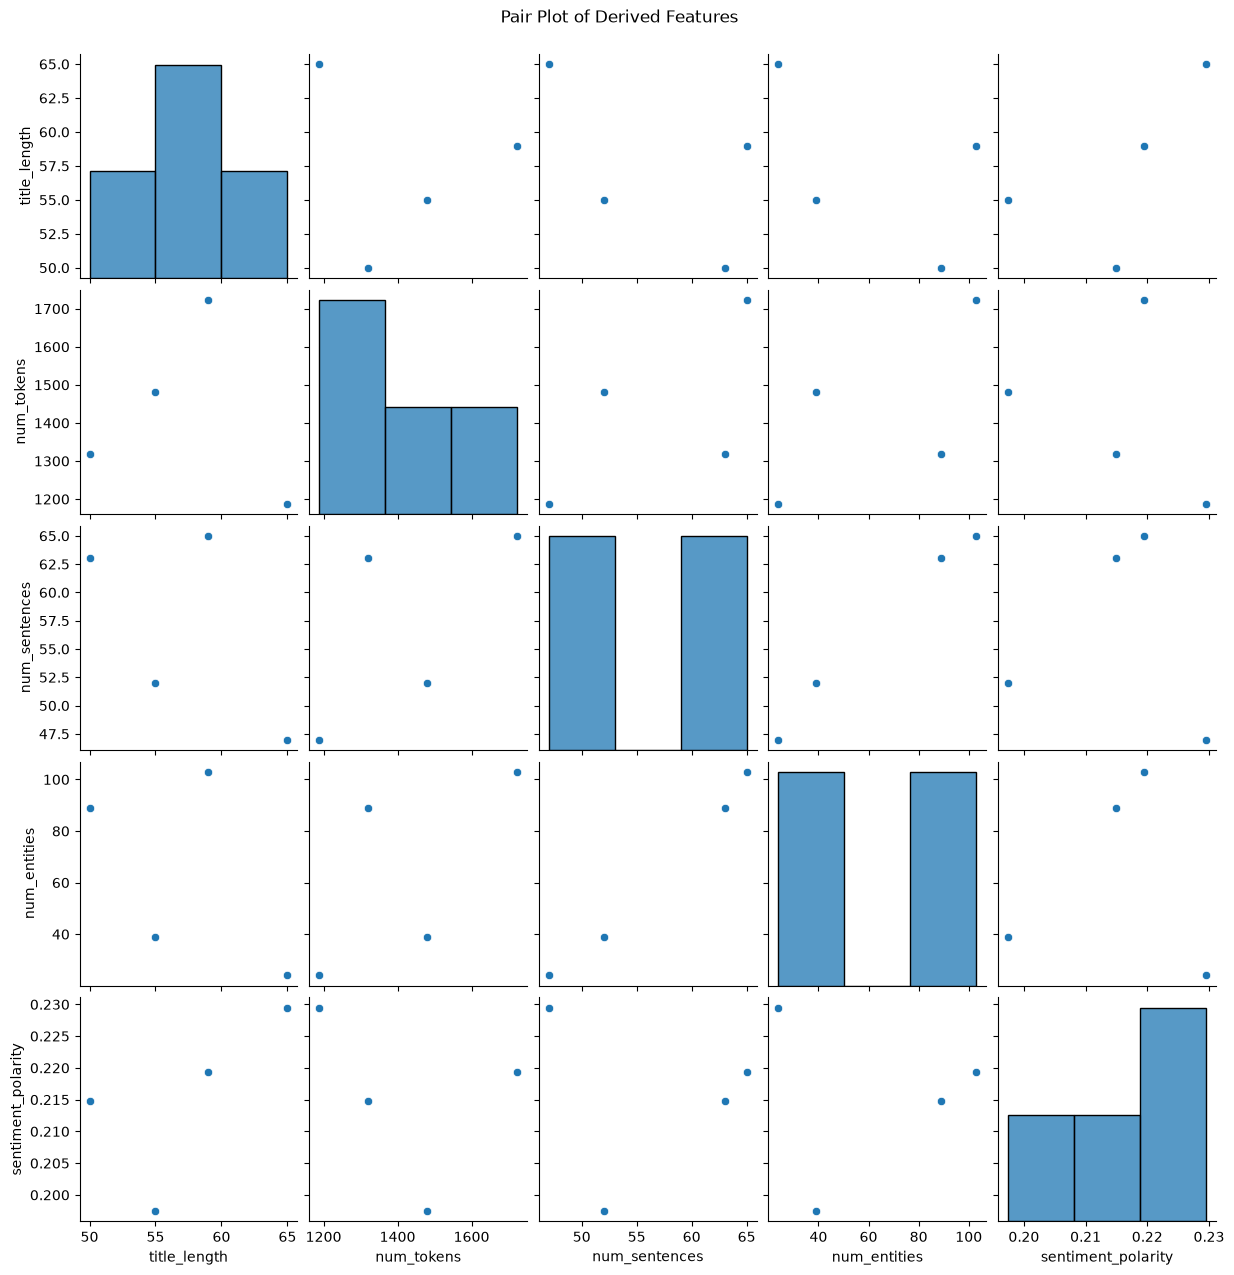

In [18]:
sns.pairplot(df[numeric_cols])

plt.suptitle(
    'Pair Plot of Derived Features',
    y=1.02
)

plt.show()

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [20]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=20
)

X = vectorizer.fit_transform(df['text'])

tfidf_df = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out()
)

tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

tfidf_sums

content       1.438203
ai            1.237947
tool          0.832933
month         0.783775
limewire      0.729283
creators      0.679878
tools         0.610609
plan          0.567677
features      0.564815
makes         0.534727
free          0.483813
creation      0.482234
use           0.415676
generate      0.332752
users         0.295475
video         0.266173
creative      0.263329
platform      0.261665
create        0.256515
generation    0.241861
dtype: float64

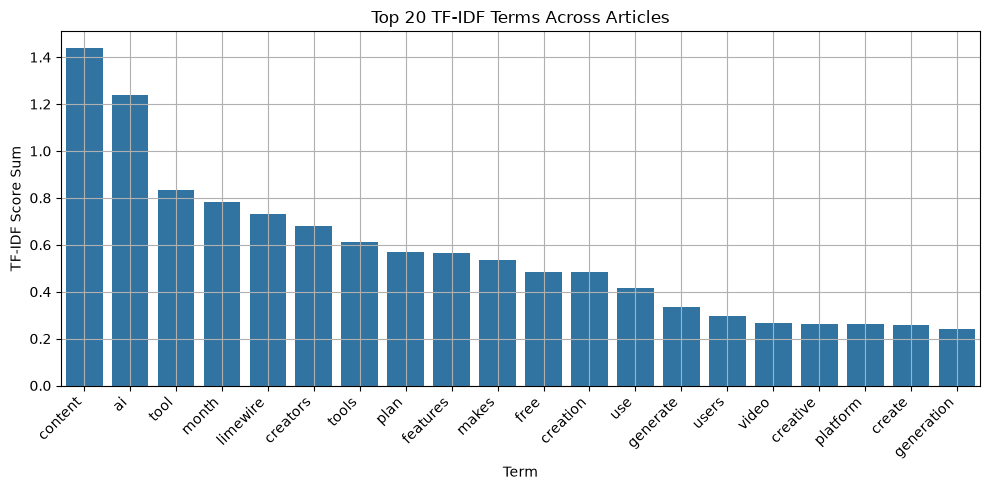

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=tfidf_sums.index,
    y=tfidf_sums.values
)

plt.title("Top 20 TF-IDF Terms Across Articles")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")

plt.xticks(rotation=45, ha='right')

plt.grid(True)
plt.tight_layout()

plt.show()

In [22]:
df.to_csv("scraped_articles.csv", index=False)

In [23]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (4, 10)

Columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']

Missing values:
url                       0
title                     0
text                      0
num_tokens                0
num_sentences             0
num_entities              0
num_nouns                 0
title_length              0
sentiment_polarity        0
sentiment_subjectivity    0
dtype: int64

First 5 rows:


,url,title,text,num_tokens,num_sentences,num_entities,num_nouns,title_length,sentiment_polarity,sentiment_subjectivity
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...,1188,47,24,321,65,0.229493,0.583603
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...,1723,65,103,420,59,0.219387,0.573587
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too...",1480,52,39,331,55,0.197417,0.436441
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...,1319,63,89,271,50,0.214853,0.564907
